In [6]:
# Author: Till Zemann
# License: MIT License

from __future__ import annotations

import os

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.nn import functional as F
from torch import optim
from tqdm import tqdm

import gymnasium as gym
import pickle as pkl
print(torch.__version__)
from net.a2c import A2C
# gen_a2c_table_bold_sci.py
from pathlib import Path

1.12.0


In [9]:
simple_type = 'rnn'
ei_type = 'dann_adam'
colors = ['#FA7F72', '#A84499', '#183319', '#20B2AA']
config_names = ['Simple', 'EISep(A)', 'EISep(C)', 'EISep(A+C)']
npy_path = Path(f"./rl/result/lunarlander/simple_{simple_type}_ei_{ei_type}/reward_ars.npy")

In [10]:


# ===== Your settings =====
actor_lrs  = [0.0003, 0.001, 0.003]
critic_lrs = [0.0015, 0.005, 0.015]
configurations = ['simple', 'eisep_actor', 'eisep_critic', 'eisep_all']  # top->bottom order

out_tex  = Path("./rl/result/lunarlander/simple_rnn_ei_eisep/a2c_lunarlander_table.tex")

# ===== Load & aggregate =====
reward_ars = np.load(npy_path)
reward_ar_flatten = reward_ars.reshape(
    len(actor_lrs), len(critic_lrs), len(configurations), -1
)
mean_r = reward_ar_flatten.mean(axis=-1)
ste_r  = reward_ar_flatten.std(axis=-1, ddof=0) / np.sqrt(reward_ar_flatten.shape[-1])

# ===== Formatting helpers =====
def fmt_num(x: float) -> str:
    return f"{x:.2f}"

def fmt_lr(x: float) -> str:
    """Return scientific notation in LaTeX form."""
    exp = int(np.floor(np.log10(x)))
    base = x / (10**exp)
    return f"{base:g}\\times10^{{{exp}}}"
    # if abs(base - 1) < 1e-8:
    #     return f"10^{{{exp}}}"
    # else:
    #     return f"{base:g}\\times10^{{{exp}}}"

def bold_math(text: str) -> str:
    """Wrap inside math mode with boldface."""
    return f"$\\mathbf{{{text.strip('$')}}}$"


# ===== Build one table cell =====
def cell_block(i_actor: int, j_critic: int, best_idx: int) -> str:
    """Create four-line cell; bold the best configuration."""
    lines = []
    for k in range(len(configurations)):
        m = fmt_num(mean_r[i_actor, j_critic, k])
        s = fmt_num(ste_r[i_actor, j_critic, k])
        txt = f"${m} \\pm {s}$"
        if k == best_idx:
            txt = bold_math(txt)
        lines.append(txt)
    return "\\makecell[tc]{" + "\\\\[1pt]".join(lines) + "}"

# ===== Determine best config per (actor, critic) pair =====
# We assume higher mean reward = better
best_config_idx = np.argmax(mean_r, axis=-1)  # shape (len(actor), len(critic))

# ===== Build LaTeX table =====
lines = []
lines.append("\\begin{table}[t]")
lines.append("  \\centering")
lines.append("  \\caption{Best performance per model for the Lunar Lander task with corresponding learning rates (mean $\pm$ SE. Each configuration is run with $n=5$ different seeds, and each seed is tested using $n=20$ different seeds).}")
lines.append("  \\label{tab:lunarlander}")
lines.append("  \\setlength{\\tabcolsep}{3pt}")
lines.append("  \\renewcommand{\\arraystretch}{0.9}")
lines.append("  \\scriptsize")
lines.append("  \\begin{tabular}{lccc}")
lines.append("    \\toprule")
actor_hdr = " & ".join([f"$\\mathbf{{{fmt_lr(a)}}}$" for a in actor_lrs])
lines.append(f"    \\textbf{{lr(C) $\\backslash$ lr(A)}} & {actor_hdr} \\\\")
lines.append("    \\midrule")

for j, c in enumerate(critic_lrs):
    row_cells = [f"$\\mathbf{{{fmt_lr(c)}}}$"]
    for i in range(len(actor_lrs)):
        row_cells.append(cell_block(i, j, best_config_idx[i, j]))
    lines.append("    " + " & ".join(row_cells) + " \\\\")
    if j < len(critic_lrs) - 1:
        lines.append("    \\midrule")

lines.append("    \\bottomrule")
lines.append("  \\end{tabular}")
lines.append("")
lines.append("  \\vspace{3pt}")
lines.append("  \\textit{Order in each cell (top to bottom):} "
             + ", ".join(config_names) + ".")
lines.append("\\end{table}")

out_tex.write_text("\n".join(lines), encoding="utf-8")
print(f"[OK] Wrote LaTeX table with bold best entries to {out_tex.resolve()}")


[OK] Wrote LaTeX table with bold best entries to /home/geert/neurogym/docs/examples/rl/result/lunarlander/simple_rnn_ei_eisep/a2c_lunarlander_table.tex


[OK] Saved: result/lunarlander/simple_rnn_ei_fixed_entryei/a2c_heatmaps_per_config.*
[OK] Saved: result/lunarlander/simple_rnn_ei_fixed_entryei/a2c_heatmap_best_over_config.*


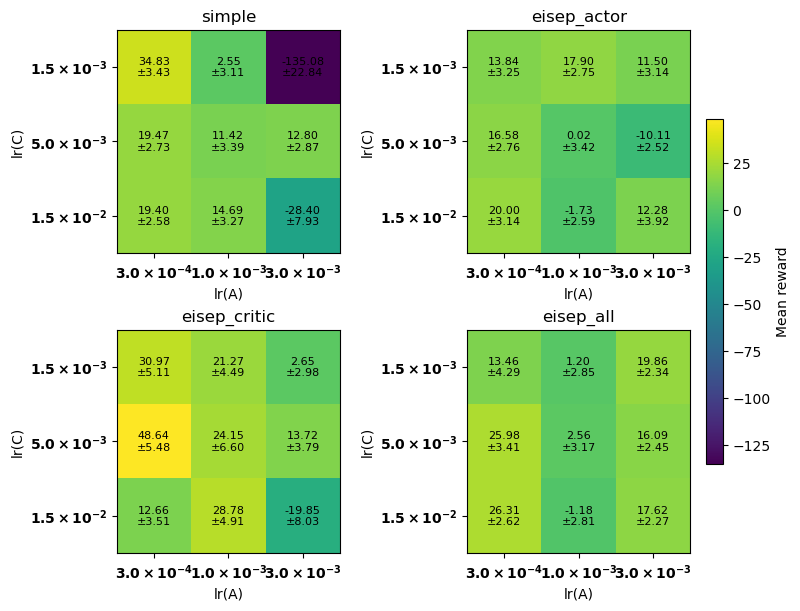

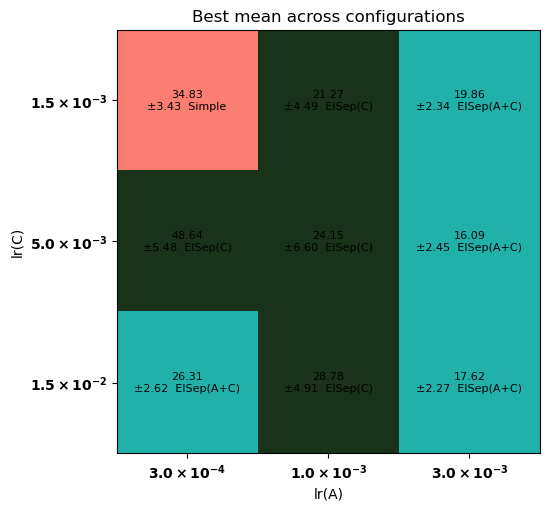

In [4]:
# gen_a2c_heatmaps.py
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.patches as mpatches
# ===== Your settings =====
actor_lrs  = [0.0003, 0.001, 0.003]
critic_lrs = [0.0015, 0.005, 0.015]
configurations = ['simple', 'eisep_actor', 'eisep_critic', 'eisep_all']  # order matters
short_cfg = ['Simple', 'EISep(A)', 'EISep(C)', 'EISep(A+C)']

out_dir  = Path("./result/lunarlander/simple_rnn_ei_fixed_entryei")
out_dir.mkdir(parents=True, exist_ok=True)

# ===== Load & aggregate =====
reward_ars = np.load(npy_path)  # any original shape as long as totals match
reward_ar_flatten = reward_ars.reshape(
    len(actor_lrs), len(critic_lrs), len(configurations), -1
)  # [actor, critic, config, trial]
mean_r = reward_ar_flatten.mean(axis=-1)  # [actor, critic, config]
ste_r  = reward_ar_flatten.std(axis=-1, ddof=0) / np.sqrt(reward_ar_flatten.shape[-1])

# ===== Helpers =====
def sci_lr(x: float) -> str:
    """Return LR as TeX-like '1.0×10^{-3}' wrapped in math mode for nice ticks."""
    exp = int(np.floor(np.log10(x)))
    base = x / (10 ** exp)
    return rf"$\mathbf{{{base:.1f}\times10^{{{exp}}}}}$"

def annotate_cell(ax, i_row, j_col, text, fontsize=8):
    ax.text(j_col, i_row, text, ha='center', va='center', fontsize=fontsize)

def grid_from_config(k_cfg: int):
    """
    Return (M_mean, M_se) for one configuration as [rows=critic, cols=actor].
    mean_r[:,:,k] is [actor, critic]; transpose to [critic, actor].
    """
    M_mean = mean_r[:, :, k_cfg].T
    M_se   = ste_r[:, :, k_cfg].T
    return M_mean, M_se

# Shared color scale across all configs for fair visual comparison
all_means = np.concatenate([grid_from_config(k)[0].ravel() for k in range(len(configurations))])
vmin, vmax = float(np.nanmin(all_means)), float(np.nanmax(all_means))

# ===== (1) 2×2 heatmaps: one per configuration =====
fig, axes = plt.subplots(2, 2, figsize=(8, 6), constrained_layout=True)
axes = axes.ravel()

for k, cfg in enumerate(configurations):
    ax = axes[k]
    M_mean, M_se = grid_from_config(k)

    im = ax.imshow(M_mean, vmin=vmin, vmax=vmax, aspect='equal')  # default cmap
    # Annotations: "mean±SE" with two decimals
    for r in range(M_mean.shape[0]):           # rows = critic
        for c in range(M_mean.shape[1]):       # cols = actor
            annotate_cell(ax, r, c, f"{M_mean[r, c]:.2f}\n±{M_se[r, c]:.2f}", fontsize=8)

    # Ticks with scientific notation labels
    ax.set_xticks(np.arange(len(actor_lrs)))
    ax.set_yticks(np.arange(len(critic_lrs)))
    ax.set_xticklabels([sci_lr(a) for a in actor_lrs], rotation=0)
    ax.set_yticklabels([sci_lr(c) for c in critic_lrs])

    ax.set_xlabel(r"lr(A)")
    ax.set_ylabel(r"lr(C)")
    ax.set_title(cfg)

# One shared colorbar
cbar = fig.colorbar(im, ax=axes, fraction=0.025, pad=0.02)
cbar.set_label("Mean reward")

fig.savefig(out_dir / "a2c_heatmaps_per_config.png", dpi=300)
fig.savefig(out_dir / "a2c_heatmaps_per_config.pdf")
print("[OK] Saved:", out_dir / "a2c_heatmaps_per_config.*")

# ===== (2) Best-over-config heatmap =====
# For each (actor, critic), find best config by mean; build grid with best means and labels
best_idx_ac = np.argmax(mean_r, axis=-1)    # shape [actor, critic]
best_mean_ac = np.max(mean_r, axis=-1)      # shape [actor, critic]
best_se_ac   = ste_r[np.arange(len(actor_lrs))[:,None],
                     np.arange(len(critic_lrs))[None,:],
                     best_idx_ac]           # matching SEs

# Convert to [critic, actor] for plotting
best_mean_grid = best_mean_ac.T
best_se_grid   = best_se_ac.T
best_idx_grid  = best_idx_ac.T  # integers in [0..3]


cmap = ListedColormap(colors)
norm = BoundaryNorm(boundaries=[-0.5, 0.5, 1.5, 2.5, 3.5], ncolors=4)

fig2, ax2 = plt.subplots(1, 1, figsize=(6, 5), constrained_layout=True)
im2 = ax2.imshow(best_idx_grid,  cmap=cmap, norm=norm, aspect='equal')

# Annotate with "mean±SE (CFG)"
for r in range(best_mean_grid.shape[0]):
    for c in range(best_mean_grid.shape[1]):
        cfg_lab = short_cfg[int(best_idx_grid[r, c])]
        annotate_cell(ax2, r, c, f"{best_mean_grid[r, c]:.2f}\n±{best_se_grid[r, c]:.2f}  {cfg_lab}", fontsize=8)

ax2.set_xticks(np.arange(len(actor_lrs)))
ax2.set_yticks(np.arange(len(critic_lrs)))
ax2.set_xticklabels([sci_lr(a) for a in actor_lrs])
ax2.set_yticklabels([sci_lr(c) for c in critic_lrs])
ax2.set_xlabel(r"lr(A)")
ax2.set_ylabel(r"lr(C)")
ax2.set_title("Best mean across configurations")
patches = [mpatches.Patch(color=colors[i], label=config_names[i]) for i in range(4)]
# ax2.legend(handles=patches, loc='upper left', frameon=False)
# cbar2 = fig2.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)
# cbar2.set_label("Mean reward")

fig2.savefig(out_dir / "a2c_heatmap_best_over_config.png", dpi=300)
fig2.savefig(out_dir / "a2c_heatmap_best_over_config.pdf")
print("[OK] Saved:", out_dir / "a2c_heatmap_best_over_config.*")


In [11]:
# gen_best_per_model_table.py
import numpy as np
from pathlib import Path

actor_lrs  = [0.0003, 0.001, 0.003]
critic_lrs = [0.0015, 0.005, 0.015]
configs    = ['Simple', 'EISep(A)', 'EISep(C)', 'EISep(A+C)']  # display names
out_tex    = Path(f"./rl/result/lunarlander/simple_{simple_type}_ei_{ei_type}/best_per_model_table.tex")

# load and aggregate  [actor, critic, config, trial]
reward_ars = np.load(npy_path)
reward = reward_ars.reshape(len(actor_lrs), len(critic_lrs), len(configs), -1)
mean_r = reward.mean(axis=-1)                              # [A, C, K]
se_r   = reward.std(axis=-1, ddof=0) / np.sqrt(reward.shape[-1])

def sci_str(x: float) -> str:
    exp  = int(np.floor(np.log10(x)))
    base = x / (10 ** exp)
    return f"${base:.1f}\\times10^{{{exp}}}$"

def best_for_config(k: int):
    m = mean_r[:, :, k]
    iA, iC = np.unravel_index(np.argmax(m), m.shape)
    return iA, iC, mean_r[iA, iC, k], se_r[iA, iC, k]

lines = []
lines.append("\\begin{table}[t]")
lines.append("  \\centering")
lines.append("  \\caption{Best performance per model with corresponding learning rates (mean $\\pm$ SE, $n=5$).}")
lines.append("  \\label{tab:best_per_model}")
lines.append("  \\small")
lines.append("  \\begin{tabular}{lccc}")
lines.append("    \\toprule")
lines.append("    \\textbf{Model} & \\textbf{Best lr(A)} & \\textbf{Best lr(C)} & \\textbf{Mean $\\pm$ SE} \\\\")
lines.append("    \\midrule")

best_idx = np.argmax(np.max(mean_r, axis=(0,1)))  # per config
print("Best overall config index:", best_idx)
def bold_math(text: str) -> str:
    """Wrap inside math mode with boldface."""
    return f"$\\mathbf{{{text.strip('$')}}}$"


for k, name in enumerate(configs):
    ia, ic, m, s = best_for_config(k)
    lr_a = sci_str(actor_lrs[ia])
    lr_c = sci_str(critic_lrs[ic])
    mean_ste_txt = f"${m:.2f} \\pm {s:.2f}$"
    if k == best_idx:
        mean_ste_txt = bold_math(mean_ste_txt)
    lines.append(f"    {name} & {lr_a} & {lr_c} & {mean_ste_txt} \\\\")


lines.append("    \\bottomrule")
lines.append("  \\end{tabular}")
lines.append("\\end{table}")

out_tex.write_text("\n".join(lines), encoding="utf-8")
print(f"[OK] wrote {out_tex.resolve()}")


Best overall config index: 1
[OK] wrote /home/geert/neurogym/docs/examples/rl/result/lunarlander/simple_rnn_ei_dann_adam/best_per_model_table.tex
